In [4]:
import pandas as pd

In [7]:
df

,Crop,Temperature_C,Humidity_pct,Rainfall_mm,Soil_Moisture_pct,Pest_Risk_Pct,Risk_Level,Likely_Pest,Best_Pesticide
0,Sugarcane,22.3,62.3,0.0,64.0,2.0,Low,No Significant Pest,No Spray Needed (monitor only)
1,Millets,25.7,70.3,0.0,28.0,47.5,Medium,Shoot Fly,Thiamethoxam 30% FS
2,Pulses,22.1,76.2,3.9,29.5,66.5,High,Aphid,Thiamethoxam 25% WG
3,Tobacco,26.1,79.2,0.0,19.0,64.9,High,Aphid,Imidacloprid 17.8% SL
4,Wheat,25.4,36.5,5.5,36.9,28.5,Low,Termite,Chlorpyrifos 20% EC
...,...,...,...,...,...,...,...,...,...
5495,Cotton,36.3,77.6,110.0,29.2,16.1,Low,Whitefly,Diafenthiuron 50% WP
5496,Wheat,17.4,38.2,4.9,26.8,21.4,Low,Aphid,Imidacloprid 17.8% SL
5497,Pulses,28.7,87.8,40.1,24.7,44.3,Medium,Pod Borer (Helicoverpa),Emamectin Benzoate 5% SG
5498,Barley,12.1,38.1,12.5,28.1,5.1,Low,No Significant Pest,No Spray Needed (monitor only)


In [6]:

df=pd.read_csv('crop_pest_dataset.csv')

In [ ]:
df_numerical=df.iloc[:,:-3]

In [13]:
df_numerical

,Crop,Temperature_C,Humidity_pct,Rainfall_mm,Soil_Moisture_pct,Pest_Risk_Pct
0,Sugarcane,22.3,62.3,0.0,64.0,2.0
1,Millets,25.7,70.3,0.0,28.0,47.5
2,Pulses,22.1,76.2,3.9,29.5,66.5
3,Tobacco,26.1,79.2,0.0,19.0,64.9
4,Wheat,25.4,36.5,5.5,36.9,28.5
...,...,...,...,...,...,...
5495,Cotton,36.3,77.6,110.0,29.2,16.1
5496,Wheat,17.4,38.2,4.9,26.8,21.4
5497,Pulses,28.7,87.8,40.1,24.7,44.3
5498,Barley,12.1,38.1,12.5,28.1,5.1


**EDA**

In [14]:
import plotly.express as px

In [15]:
df_numerical

,Crop,Temperature_C,Humidity_pct,Rainfall_mm,Soil_Moisture_pct,Pest_Risk_Pct
0,Sugarcane,22.3,62.3,0.0,64.0,2.0
1,Millets,25.7,70.3,0.0,28.0,47.5
2,Pulses,22.1,76.2,3.9,29.5,66.5
3,Tobacco,26.1,79.2,0.0,19.0,64.9
4,Wheat,25.4,36.5,5.5,36.9,28.5
...,...,...,...,...,...,...
5495,Cotton,36.3,77.6,110.0,29.2,16.1
5496,Wheat,17.4,38.2,4.9,26.8,21.4
5497,Pulses,28.7,87.8,40.1,24.7,44.3
5498,Barley,12.1,38.1,12.5,28.1,5.1


In [16]:
import numpy as np

In [17]:
np.mean(df[df['Crop']=='Tobacco']['Temperature_C'])

np.float64(21.5846)

In [32]:
def mean_temp(df,crop):
    return np.mean(df[df['Crop']==crop]['Temperature_C'])

In [ ]:
df_numerical['mean_temp']=mean_temp(df_numerical,df_numerical['Crop'])

<Axes: xlabel='Crop'>

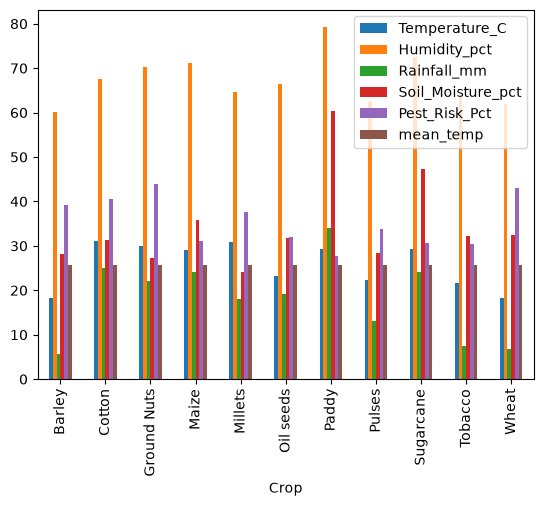

In [49]:
df_numerical.groupby(by='Crop').mean().plot(kind='bar')

In [51]:
df_numerical.drop(columns='mean_temp',inplace=True)

In [57]:
df_numerical['Rainfall_mm'].value_counts()

Rainfall_mm
0.0      1975
120.0      38
25.0       31
1.2        25
0.2        25
         ... 
61.5        1
64.6        1
99.0        1
107.9       1
58.0        1
Name: count, Length: 837, dtype: int64

In [19]:
from sklearn.preprocessing import OneHotEncoder

In [29]:
# Data preprocessing
one_crop=OneHotEncoder(sparse_output=False)
df_numerical_encoded=one_crop.fit_transform(df_numerical[['Crop']])

In [26]:
df_numerical_encoded=pd.DataFrame(df_numerical_encoded,columns=crop_columns)

In [23]:
crop_columns=[
    '_'.join(map(str, col)) if isinstance(col, tuple) else str(col)
    for col in df_numerical_encoded.columns
]

In [70]:
crop_columns

['Barley',
 'Cotton',
 'Ground Nuts',
 'Maize',
 'Millets',
 'Oil seeds',
 'Paddy',
 'Pulses',
 'Sugarcane',
 'Tobacco',
 'Wheat']

In [31]:
df_numerical_encoded=pd.DataFrame(df_numerical_encoded,columns=crop_columns)

In [32]:
df_numerical_encoded

,Barley,Cotton,Ground Nuts,Maize,Millets,Oil seeds,Paddy,Pulses,Sugarcane,Tobacco,Wheat
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
5495,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5496,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5497,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
5498,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [33]:
# Concatenate with our df_numerical:
df_numerical=pd.concat((df_numerical,df_numerical_encoded),axis=1)

In [34]:
df_numerical.drop(columns='Crop',inplace=True)

In [40]:
df_numerical

,Temperature_C,Humidity_pct,Rainfall_mm,Soil_Moisture_pct,Pest_Risk_Pct,Barley,Cotton,Ground Nuts,Maize,Millets,Oil seeds,Paddy,Pulses,Sugarcane,Tobacco,Wheat
0,22.3,62.3,0.0,64.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,25.7,70.3,0.0,28.0,47.5,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,22.1,76.2,3.9,29.5,66.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,26.1,79.2,0.0,19.0,64.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,25.4,36.5,5.5,36.9,28.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5495,36.3,77.6,110.0,29.2,16.1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5496,17.4,38.2,4.9,26.8,21.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5497,28.7,87.8,40.1,24.7,44.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
5498,12.1,38.1,12.5,28.1,5.1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# X:
x=df_numerical.drop(columns=['Pest_Risk_Pct'])
y=df_numerical['']

In [84]:
y

0        2.0
1       47.5
2       66.5
3       64.9
4       28.5
        ... 
5495    16.1
5496    21.4
5497    44.3
5498     5.1
5499    61.3
Name: Pest_Risk_Pct, Length: 5500, dtype: float64

In [86]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=32)

In [108]:
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [88]:
y_pred

array([45.1 , 26.5 , 10.06, ..., 41.98, 46.  , 19.86], shape=(1100,))

In [90]:
y_test.shape

(1100,)

In [ ]:
knr=KNeighborsRegressor()
knr.fit(x_train,y_train)
y_pred=knr.predict(x_test)

In [96]:
from sklearn.metrics import mean_squared_error,r2_score

In [103]:
mean_squared_error(y_pred=y_pred,y_true=y_test)

156.96467272727273

In [97]:
r2_score(y_pred=y_pred,y_true=y_test)

0.47137520155071355

In [106]:
dtf=DecisionTreeRegressor()
dtf.fit(x_train,y_train)
y_pred=dtf.predict(x_test)
r2_score(y_pred=y_pred,y_true=y_test)

0.6750446684351783

In [101]:
svr=SVR()
svr.fit(x_train,y_train)
y_pred=svr.predict(x_test)
r2_score(y_pred=y_pred,y_true=y_test)

0.34299263689628523

In [107]:
import pickle 
pickle.dump(dtf,open('dtf.pkl','wb'))
pickle.dump(one_crop,open('one_crop.pkl','wb'))

In [109]:
lr=LinearRegression()
lr.fit(x_train,y_train)
y_pred=lr.predict(x_test)
r2_score(y_pred=y_pred,y_true=y_test)

0.376078398002053

In [111]:
df_category=df.drop(columns='Pest_Risk_Pct')

In [112]:
df_category

,Crop,Temperature_C,Humidity_pct,Rainfall_mm,Soil_Moisture_pct,Risk_Level,Likely_Pest,Best_Pesticide
0,Sugarcane,22.3,62.3,0.0,64.0,Low,No Significant Pest,No Spray Needed (monitor only)
1,Millets,25.7,70.3,0.0,28.0,Medium,Shoot Fly,Thiamethoxam 30% FS
2,Pulses,22.1,76.2,3.9,29.5,High,Aphid,Thiamethoxam 25% WG
3,Tobacco,26.1,79.2,0.0,19.0,High,Aphid,Imidacloprid 17.8% SL
4,Wheat,25.4,36.5,5.5,36.9,Low,Termite,Chlorpyrifos 20% EC
...,...,...,...,...,...,...,...,...
5495,Cotton,36.3,77.6,110.0,29.2,Low,Whitefly,Diafenthiuron 50% WP
5496,Wheat,17.4,38.2,4.9,26.8,Low,Aphid,Imidacloprid 17.8% SL
5497,Pulses,28.7,87.8,40.1,24.7,Medium,Pod Borer (Helicoverpa),Emamectin Benzoate 5% SG
5498,Barley,12.1,38.1,12.5,28.1,Low,No Significant Pest,No Spray Needed (monitor only)


In [115]:
x_category=df.loc[:,:'Risk_Level']

In [118]:
x_category=x_category.drop(columns='Risk_Level')

In [119]:
x_category

,Crop,Temperature_C,Humidity_pct,Rainfall_mm,Soil_Moisture_pct,Pest_Risk_Pct
0,Sugarcane,22.3,62.3,0.0,64.0,2.0
1,Millets,25.7,70.3,0.0,28.0,47.5
2,Pulses,22.1,76.2,3.9,29.5,66.5
3,Tobacco,26.1,79.2,0.0,19.0,64.9
4,Wheat,25.4,36.5,5.5,36.9,28.5
...,...,...,...,...,...,...
5495,Cotton,36.3,77.6,110.0,29.2,16.1
5496,Wheat,17.4,38.2,4.9,26.8,21.4
5497,Pulses,28.7,87.8,40.1,24.7,44.3
5498,Barley,12.1,38.1,12.5,28.1,5.1


In [123]:
x_category=pd.concat((x_category,df_numerical_encoded),axis=1)

In [126]:
x_category.drop(columns=['Crop','Pest_Risk_Pct'],inplace=True)

In [130]:
df_category

,Crop,Temperature_C,Humidity_pct,Rainfall_mm,Soil_Moisture_pct,Risk_Level,Likely_Pest,Best_Pesticide
0,Sugarcane,22.3,62.3,0.0,64.0,Low,No Significant Pest,No Spray Needed (monitor only)
1,Millets,25.7,70.3,0.0,28.0,Medium,Shoot Fly,Thiamethoxam 30% FS
2,Pulses,22.1,76.2,3.9,29.5,High,Aphid,Thiamethoxam 25% WG
3,Tobacco,26.1,79.2,0.0,19.0,High,Aphid,Imidacloprid 17.8% SL
4,Wheat,25.4,36.5,5.5,36.9,Low,Termite,Chlorpyrifos 20% EC
...,...,...,...,...,...,...,...,...
5495,Cotton,36.3,77.6,110.0,29.2,Low,Whitefly,Diafenthiuron 50% WP
5496,Wheat,17.4,38.2,4.9,26.8,Low,Aphid,Imidacloprid 17.8% SL
5497,Pulses,28.7,87.8,40.1,24.7,Medium,Pod Borer (Helicoverpa),Emamectin Benzoate 5% SG
5498,Barley,12.1,38.1,12.5,28.1,Low,No Significant Pest,No Spray Needed (monitor only)


In [8]:
y_category=df[['Likely_Pest','Best_Pesticide']]

In [9]:
from sklearn.preprocessing import LabelEncoder
le_likely_pest=LabelEncoder()
y_trf_pest=le_likely_pest.fit_transform(y_category.iloc[:,0])

In [12]:
import numpy as np

In [13]:
np.unique(df['Crop'])

array(['Barley', 'Cotton', 'Ground Nuts', 'Maize', 'Millets', 'Oil seeds',
       'Paddy', 'Pulses', 'Sugarcane', 'Tobacco', 'Wheat'], dtype=object)

In [10]:
le_likely_pest.classes_

array(['Alternaria Blight', 'Aphid', 'Blast', 'Brown Planthopper',
       'Earhead Bug', 'Early Shoot Borer', 'Fall Armyworm',
       'Frog-eye Leaf Spot', 'Girdle Beetle', 'Jassid', 'Leaf Miner',
       'Leaf Spot (Tikka)', 'Mustard Aphid', 'No Significant Pest',
       'Pink Bollworm', 'Pod Borer (Helicoverpa)', 'Red Rot', 'Shoot Fly',
       'Spodoptera Caterpillar', 'Stem Borer', 'Termite',
       'Turcicum Leaf Blight', 'Whitefly', 'Wilt', 'Woolly Aphid',
       'Yellow Rust'], dtype=object)

In [77]:
from sklearn.preprocessing import LabelEncoder
le_best_pesticide=LabelEncoder()
y_trf_pesticide=le_best_pesticide.fit_transform(y_category.iloc[:,1])

In [78]:
le_best_pesticide.classes_

array(['Buprofezin 25% SC', 'Carbendazim 50% WP',
       'Cartap Hydrochloride 4% G', 'Chlorantraniliprole 18.5% SC',
       'Chlorpyrifos 20% EC', 'Diafenthiuron 50% WP', 'Dimethoate 30% EC',
       'Emamectin Benzoate 5% SG', 'Hexaconazole 5% EC',
       'Imidacloprid 17.8% SL', 'Lambda-cyhalothrin 5% EC',
       'Malathion 50% EC', 'Mancozeb 75% WP',
       'No Spray Needed (monitor only)', 'Propiconazole 25% EC',
       'Spinetoram 11.7% SC', 'Thiamethoxam 25% WG',
       'Thiamethoxam 30% FS', 'Tricyclazole 75% WP'], dtype=object)

In [151]:
dat={
    'Likely_Pest':y_trf_pest,
    'Best_Pesticide':y_trf_pesticide
}

In [155]:
y_category=pd.DataFrame(dat)

In [158]:
y_category

,Likely_Pest,Best_Pesticide
0,13,13
1,17,17
2,1,16
3,1,9
4,20,4
...,...,...
5495,22,5
5496,1,9
5497,15,7
5498,13,13


In [67]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB,BernoulliNB
from sklearn.tree import DecisionTreeClassifier

In [162]:
x_train,x_test,y_train,y_test=train_test_split(x_category,y_category,test_size=.2,random_state=42)

In [164]:
lr=LogisticRegression()
lr.fit(x_train,y_train.iloc[:,0])
y_pred=lr.predict(x_test)
accuracy_score(y_pred=y_pred,y_true=y_test.iloc[:,0])

C:\Users\Mohd Qausain\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.5845454545454546

In [2]:
le_likely_pest.classes_

NameError: name 'le_likely_pest' is not defined

In [165]:
knn=KNeighborsClassifier()
knn.fit(x_train,y_train.iloc[:,0])
y_pred=knn.predict(x_test)
accuracy_score(y_pred=y_pred,y_true=y_test.iloc[:,0])

0.40454545454545454

In [166]:
bnb=BernoulliNB()
bnb.fit(x_train,y_train.iloc[:,0])
y_pred=bnb.predict(x_test)
accuracy_score(y_pred=y_pred,y_true=y_test.iloc[:,0])

0.5863636363636363

In [168]:
mnb=MultinomialNB()
mnb.fit(x_train,y_train.iloc[:,0])
y_pred=mnb.predict(x_test)
accuracy_score(y_pred=y_pred,y_true=y_test.iloc[:,0])

0.41

In [1]:
dtc=DecisionTreeClassifier()
dtc.fit(x_train,y_train.iloc[:,0])
y_pred=dtc.predict(x_test)
accuracy_score(y_pred=y_pred,y_true=y_test.iloc[:,0])

NameError: name 'DecisionTreeClassifier' is not defined

In [ ]:
import pickle
pickle.dump(le_likely_pest,open('le_likely_pest','wb'))
pickle.dump(le_best_pesticide,open('le_best_pesticide','wb'))

In [47]:
df=pd.concat((df,df_numerical_encoded),axis=1)

In [50]:
df=df.drop(columns='Crop')

In [53]:
df.drop(columns='Risk_Level',inplace=True)

In [56]:
y=df['Best_Pesticide']
x=df.drop(columns=['Likely_Pest','Best_Pesticide'])

In [60]:
from sklearn.model_selection import train_test_split

In [65]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=32,test_size=.2)

In [63]:
from sklearn.preprocessing import LabelEncoder

In [64]:
le_best_cure=LabelEncoder()
y=le_best_cure.fit_transform(y)


In [69]:
from sklearn.metrics import accuracy_score

In [70]:
dtc_cure=DecisionTreeClassifier()
dtc_cure.fit(x_train,y_train)
y_pred=dtc_cure.predict(x_test)
accuracy_score(y_pred=y_pred,y_true=y_test)

0.9309090909090909

In [71]:
import pickle
pickle.dump(dtc_cure,open('Dtc_cure.pkl','wb'))
pickle.dump(le_best_cure,open('le_best_cure.pkl','wb'))


In [72]:
le_best_cure.classes_

array(['Buprofezin 25% SC', 'Carbendazim 50% WP',
       'Cartap Hydrochloride 4% G', 'Chlorantraniliprole 18.5% SC',
       'Chlorpyrifos 20% EC', 'Diafenthiuron 50% WP', 'Dimethoate 30% EC',
       'Emamectin Benzoate 5% SG', 'Hexaconazole 5% EC',
       'Imidacloprid 17.8% SL', 'Lambda-cyhalothrin 5% EC',
       'Malathion 50% EC', 'Mancozeb 75% WP',
       'No Spray Needed (monitor only)', 'Propiconazole 25% EC',
       'Spinetoram 11.7% SC', 'Thiamethoxam 25% WG',
       'Thiamethoxam 30% FS', 'Tricyclazole 75% WP'], dtype=object)

In [73]:
le_best_pesticide.classes_

NameError: name 'le_best_pesticide' is not defined